# What have we funded on batteries? A first look at the CORDIS data

**In short.** In the public CORDIS data, 278 Horizon Europe projects have a battery term in their title and 662 mention one anywhere. Among projects at least two years old, fellowships set aside, 68% of battery projects have a publication, against 63% across the programme. I read 20 borderline projects by hand: of the 15 that the keyword rule includes, I judged 13 not about batteries. Those cases were drawn where the rule is weakest, so this is not an error rate for the 662. The decisions this leaves to the unit are in section 8.

**The request.** A policy unit asks, through its Feedback to Policy (F2P) Correspondent: *"We need to know what we've funded on batteries and whether it's working. Can you build us something with AI?"* It asks two questions, implies a third (where the gaps are) and names a solution before any of them is defined. This notebook checks how far the public data can answer the first.

**How to read this page.** The text and the results carry the reasoning; the code is there for readers who want to check it. A reader with little time can keep to this summary, the chart in section 5 and section 8.

## 1. Data source and reuse terms

**Source.** CORDIS, the Commission's public repository of EU-funded research projects. The Horizon Europe dataset is published on [data.europa.eu](https://data.europa.eu/data/datasets/cordis-eu-research-projects-under-horizon-europe-2021-2027) as CSV archives: projects, euroSciVoc labels, publications, deliverables and report summaries.

**Reuse terms.** CORDIS releases its datasets under the CC BY 4.0 licence, in line with the Commission's reuse policy ([Decision 2011/833/EU](https://eur-lex.europa.eu/eli/dec/2011/833/oj)): reuse is allowed provided the source is credited and changes are indicated.

**Snapshot.** The files are downloaded if missing and their SHA-256 fingerprint is compared with `data/SHA256SUMS`, recorded from the archives of early October 2026 (the most recent file is dated 8 October). CORDIS republishes the dataset in place: on a later download the notebook warns and continues, and the figures quoted in the text stay those of this snapshot.

In [1]:
import sys

sys.path.insert(0, "src")

import cordis

LABELS = {
    "eu_contribution_meur": "EU contribution, EUR million",
    "start_year": "start year",
    "part": "programme part",
    "activityType": "type of organisation",
    "share_published": "share with a publication",
}

def show(table):
    """Print a table with plain column and index names."""
    if hasattr(table, "columns"):
        table = table.rename(columns=LABELS)
    print(table.rename_axis(LABELS.get(table.index.name, table.index.name)).to_string())

projects_zip = cordis.fetch_zip("cordis-HORIZONprojects-csv.zip")
publications_zip = cordis.fetch_zip("cordis-HORIZONprojectPublications-csv.zip")

projects, projects_excluded = cordis.read_from_zip(projects_zip, "project.csv")
eurosci, eurosci_excluded = cordis.read_from_zip(projects_zip, "euroSciVoc.csv")
publications, publications_excluded = cordis.read_from_zip(publications_zip, "projectPublications.csv")

for name, df, excluded in [
    ("project.csv", projects, projects_excluded),
    ("euroSciVoc.csv", eurosci, eurosci_excluded),
    ("projectPublications.csv", publications, publications_excluded),
]:
    print(f"{name:28} {len(df):>8,} rows read   {excluded:>5,} rows excluded ({excluded / (len(df) + excluded):.2%})")

project.csv                    23,756 rows read     198 rows excluded (0.83%)
euroSciVoc.csv                 53,196 rows read       0 rows excluded (0.00%)
projectPublications.csv        95,383 rows read      22 rows excluded (0.02%)


## 2. Quality check

**Rows that cannot be read.** A few free-text fields contain quotation marks that break the row. Those rows are counted above for each file, excluded and not repaired: under one percent of projects. Totals are therefore slightly under the true totals, and a lookup by project may miss a project for that reason alone.

**Coverage of the ready-made taxonomy.** CORDIS attaches European Science Vocabulary (euroSciVoc) labels to projects. If every project carried them, battery projects could be read straight off the taxonomy.

In [3]:
labelled = projects["id"].isin(eurosci["projectID"])
print(f"Projects with at least one euroSciVoc label: {labelled.sum():,} of {len(projects):,} ({labelled.mean():.1%})")
print(f"Projects without any euroSciVoc label:       {(~labelled).sum():,} ({(~labelled).mean():.1%})")

Projects with at least one euroSciVoc label: 19,793 of 23,756 (83.3%)
Projects without any euroSciVoc label:       3,963 (16.7%)


## 3. FAIR check

Against the FAIR principles (findable, accessible, interoperable, reusable; Wilkinson et al., 2016):

| Principle | What holds | What does not |
|---|---|---|
| **Findable** | Dataset catalogued on data.europa.eu with a stable identifier; each project has a persistent id and almost every project a grant DOI. | No version identifier on the CSV archives: the only way to know which snapshot was used is the fingerprint kept in this repository. |
| **Accessible** | Open download, no account, no API key; standard CSV. | Archives are republished in place, so a given snapshot is not retrievable afterwards. |
| **Interoperable** | Shared project ids across the files make joins straightforward; euroSciVoc is a controlled vocabulary. | Decimal commas and unescaped quotes need a tolerant loader; a fraction of projects carries no euroSciVoc label. |
| **Reusable** | Clear licence (CC BY 4.0 under Decision 2011/833/EU); documentation shipped inside each archive. | No change log between snapshots, so figures can move without notice. |

**What this means for the request.** The data can support a reproducible answer to "what have we funded?", provided the snapshot is pinned and the excluded rows are reported. It cannot by itself answer "is it working?".

## 4. Scope: what counts as a "battery" project?

No field in CORDIS says "this is a battery project". There are two ways to find them:

- **The ready-made taxonomy.** euroSciVoc has a label *electric batteries*. It is precise, but not every project carries labels (section 2).
- **A keyword rule.** Six terms (battery, batteries, lithium-ion, li-ion, sodium-ion, solid-state cell), searched whatever the case, including inside longer words. The unit can challenge the list term by term.

The rule is applied twice: to the **title only** (narrow: the title names batteries) and to **title + objective + keywords** (broad: batteries are mentioned somewhere). The gap between the two shows how much the definition changes the answer.

In [4]:
TERMS = ["battery", "batteries", "lithium-ion", "li-ion", "sodium-ion", "solid-state cell"]

in_title = cordis.matches_terms(projects, TERMS, ["title"])
in_text = cordis.matches_terms(projects, TERMS, ["title", "objective", "keywords"])

print(f"Narrow definition, term in the title:                    {in_title.sum():>5,} projects")
print(
    f"Broad definition, term in title, objective or keywords:  {in_text.sum():>5,} projects"
    f"  (x{in_text.sum() / in_title.sum():.1f})"
)
print(f"In the broad set but not the narrow one:                 {(in_text & ~in_title).sum():>5,} projects")

Narrow definition, term in the title:                      278 projects
Broad definition, term in title, objective or keywords:    662 projects  (x2.4)
In the broad set but not the narrow one:                   384 projects


**Reading the two counts.** Neither set is right by itself. The narrow one misses projects where batteries are one work package among others. The broad one catches single mentions, battery-free devices and the word in another sense ("a battery of tests"). The cell below sizes this grey zone: the term is not in the title and appears fewer than three times. This is where a model would help most. The cut at three mentions is mine; the distribution is printed so that the unit can move it.

In [5]:
import re

text = projects[["title", "objective", "keywords"]].fillna("").astype(str).agg(" ".join, axis=1).str.lower()
mentions = text.str.count("|".join(re.escape(t) for t in TERMS))
other_sense = text.str.contains(r"\bbattery of\b")
battery_free = text.str.contains(r"battery-free|batteryless|battery-less|battery free")
once_outside_title = in_text & ~in_title & (mentions == 1)
grey = in_text & ~in_title & (mentions < 3)

print(f"Broad set:                                              {in_text.sum():>5,}")
print(f"  term used in another sense ('a battery of ...'):        {(in_text & other_sense).sum():>5,}")
print(f"  battery-free or batteryless devices:                   {(in_text & battery_free).sum():>5,}")
print(f"  term mentioned once, outside the title:                {once_outside_title.sum():>5,}")
print(
    f"Grey zone (not in title, fewer than three mentions):    {grey.sum():>5,}"
    f"  ({grey.mean() / in_text.mean():.0%} of the broad set)"
)
grey_msca = grey & projects["fundingScheme"].str.contains("MSCA", na=False)
grey_erc = grey & projects["fundingScheme"].str.startswith("HORIZON-ERC", na=False)
print(f"  of which fellowships: {grey_msca.sum()}, ERC grants: {grey_erc.sum()}")
per_project = mentions[in_text & ~in_title].clip(upper=4).value_counts().sort_index().rename({4: "4 or more"})
print(
    "Mentions per project in the broad set, outside the title: "
    + ", ".join(f"{k}: {v}" for k, v in per_project.items())
)

print(f"Battery-free devices with the term in the title (in the narrow set): {(in_title & battery_free).sum()}")

examples = projects[in_text & other_sense].copy()
examples["snippet"] = examples["objective"].fillna("").apply(
    lambda s: next((m.group(0) for m in re.finditer(r".{0,50}battery of.{0,50}", s, flags=re.I)), "")
)
examples[["acronym", "snippet"]].head(4).style.hide(axis="index")

Broad set:                                                662
  term used in another sense ('a battery of ...'):           14
  battery-free or batteryless devices:                      23
  term mentioned once, outside the title:                  237
Grey zone (not in title, fewer than three mentions):      292  (44% of the broad set)
  of which fellowships: 83, ERC grants: 59
Mentions per project in the broad set, outside the title: 1: 237, 2: 55, 3: 30, 4 or more: 62
Battery-free devices with the term in the title (in the narrow set): 5


acronym,snippet
ConnectomesToANNs,n of how these principles impact performance on a battery of deep learning tasks. This unique methodology will
LgDel-mPFC,"t of OXT and dopamine real-time dynamics during a battery of non-social and social cognitive tests, I aim to d"
SENSE,"ng their predictability of human performance in a battery of semantic tasks. Overall, SENSE will make a soli"
CHROMSEG,questions and will exploit our recently generated battery of molecular reagents. Outcome of our work will prov


**What the taxonomy says about the same projects.** Of the 59 projects labelled *electric batteries* in euroSciVoc, 57 can be read from the file and the keyword rule catches all 57 (the other two are most likely among the rows excluded in section 2). But the label covers under a tenth of the broad set: euroSciVoc describes scientific fields, not policy themes. Agreeing a definition with the unit, and recording it as metadata, is part of the work.

In [6]:
is_battery_label = eurosci["euroSciVocPath"].str.contains("electric batteries", case=False, na=False)
battery_label = eurosci[is_battery_label]["projectID"].unique()
readable = projects["id"].isin(battery_label)

print(f"Projects labelled 'electric batteries' in euroSciVoc:            {len(battery_label):>4,}")
print(f"  of which readable in project.csv (the rest are unparseable rows): {readable.sum():>4,}")
print(f"  of which caught by the broad keyword rule:                        {(readable & in_text).sum():>4,}")
print(f"Share of the broad set that carries the label:                     {readable[in_text].mean():>5.1%}")

Projects labelled 'electric batteries' in euroSciVoc:              59
  of which readable in project.csv (the rest are unparseable rows):   57
  of which caught by the broad keyword rule:                          57
Share of the broad set that carries the label:                      8.6%


**Does "what we funded" include the partnership?** The calls of the BATT4EU partnership sit under Cluster 5, Destination 2 of the work programme, whose topic identifiers can be counted; they also hold other calls, so the count is an approximation. Whether those projects, the Marie Skłodowska-Curie fellowships and the ERC grants count is for the unit to decide.

In [7]:
import pandas as pd

scope = projects[in_text].copy()
scope["start_year"] = pd.to_datetime(scope["startDate"], errors="coerce").dt.year
scope["is_msca"] = scope["fundingScheme"].str.contains("MSCA", na=False)
scope["is_d2"] = scope["topics"].str.contains(r"CL5-20\d\d-(?:\d\d-)?D2", na=False)

print(f"Broad set: {len(scope):,} projects")
print(f"  under a Cluster 5 / Destination 2 topic (where the BATT4EU calls sit): {scope['is_d2'].sum():>4,}")
print(
    f"  Marie Skłodowska-Curie fellowships and networks:                        "
    f"{scope['is_msca'].sum():>4,}  ({scope['is_msca'].mean():.0%})"
)
print(
    f"  ERC grants:                                                             "
    f"{scope['fundingScheme'].str.startswith('HORIZON-ERC').sum():>4,}"
)

Broad set: 662 projects
  under a Cluster 5 / Destination 2 topic (where the BATT4EU calls sit):   98
  Marie Skłodowska-Curie fellowships and networks:                         221  (33%)
  ERC grants:                                                              103


## 5. What was funded, for the broad definition

Taking the broad set as the working scope: projects and EU contribution by start year, by part of the programme (pillar and cluster) and by instrument. Amounts are the maximum EU contribution in each grant agreement, not the amount paid. Fellowships are shown apart: they are a third of the set. Figures are those of the CORDIS export of early October 2026, without the unreadable rows of section 2. The last two years are incomplete: projects from recent calls are still being signed.

In [8]:
by_year = (
    scope.groupby("start_year")
    .agg(
        projects=("id", "size"),
        eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6),
        fellowships=("is_msca", "sum"),
    )
    .round(1)
)
by_year.index = by_year.index.astype(int)
show(by_year)
print(f"\nTotal: {len(scope):,} projects, EUR {scope['ecMaxContribution'].sum() / 1e9:.2f} billion of EU contribution")

            projects  EU contribution, EUR million  fellowships
start year                                                     
2022              94                         337.7           14
2023             156                         654.9           38
2024             137                         502.9           42
2025             109                         316.4           47
2026             135                         412.2           53
2027              31                          29.7           27

Total: 662 projects, EUR 2.25 billion of EU contribution


In [9]:
PROGRAMME_PART = {
    "HORIZON.1.1": "Pillar I - ERC",
    "HORIZON.1.2": "Pillar I - Marie Skłodowska-Curie",
    "HORIZON.1.3": "Pillar I - Research infrastructures",
    "HORIZON.2.1": "Pillar II - Cluster 1 Health",
    "HORIZON.2.4": "Pillar II - Cluster 4 Digital, industry, space",
    "HORIZON.2.5": "Pillar II - Cluster 5 Climate, energy, mobility",
    "HORIZON.2.6": "Pillar II - Cluster 6 Food, bioeconomy, environment",
    "HORIZON.3.1": "Pillar III - European Innovation Council",
    "HORIZON.3.2": "Pillar III - European innovation ecosystems",
    "HORIZON.3.3": "Pillar III - European Institute of Innovation and Technology",
    "HORIZON.4.1": "Widening participation",
}
by_part = (
    scope.assign(part=scope["legalBasis"].map(PROGRAMME_PART).fillna(scope["legalBasis"]))
    .groupby("part")
    .agg(projects=("id", "size"), eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6))
    .sort_values("eu_contribution_meur", ascending=False)
    .round(1)
)
show(by_part)

                                                              projects  EU contribution, EUR million
programme part                                                                                      
Pillar II - Cluster 5 Climate, energy, mobility                    178                        1266.1
Pillar II - Cluster 4 Digital, industry, space                      56                         370.3
Pillar III - European Innovation Council                            87                         215.3
Pillar I - ERC                                                     103                         131.0
Pillar I - Marie Skłodowska-Curie                                  214                         125.7
Pillar II - Cluster 6 Food, bioeconomy, environment                  6                          59.2
Pillar III - European Institute of Innovation and Technology         1                          48.0
Widening participation                                              15                     

**Research or demonstration?** The funding instrument says what kind of work was funded: research and innovation actions (RIA) explore, innovation actions (IA) demonstrate at scale, the European Innovation Council (EIC) backs start-ups, the European Research Council (ERC) funds frontier science, coordination and support actions (CSA) fund networks, and fellowships train researchers. A few fellowships sit under other programme parts in the table above (214 against 221). Of the funding views, the chart below is the one I would show the unit first.

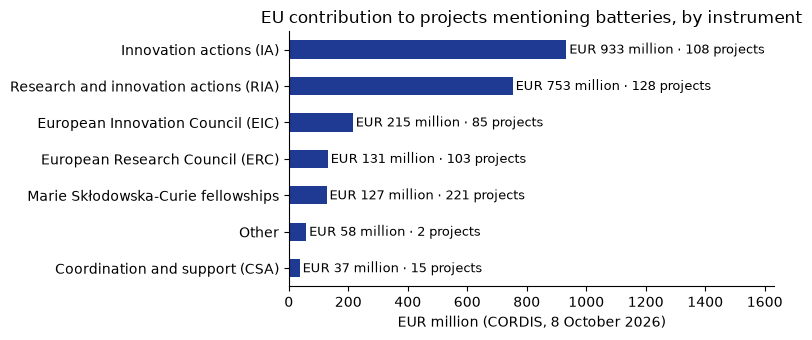

                                       projects  EU contribution, EUR million
instrument                                                                   
Innovation actions (IA)                     108                         933.0
Research and innovation actions (RIA)       128                         752.7
European Innovation Council (EIC)            85                         215.2
European Research Council (ERC)             103                         131.0
Marie Skłodowska-Curie fellowships          221                         126.8
Other                                         2                          58.4
Coordination and support (CSA)               15                          36.6


In [11]:
import matplotlib.pyplot as plt

INSTRUMENT = {
    "HORIZON-IA": "Innovation actions (IA)",
    "HORIZON-RIA": "Research and innovation actions (RIA)",
    "HORIZON-JU-IA": "Innovation actions (IA)",
    "HORIZON-JU-RIA": "Research and innovation actions (RIA)",
    "HORIZON-CSA": "Coordination and support (CSA)",
    "HORIZON-JU-CSA": "Coordination and support (CSA)",
}
def instrument(scheme):
    if "MSCA" in scheme:
        return "Marie Skłodowska-Curie fellowships"
    if scheme.startswith("HORIZON-ERC"):
        return "European Research Council (ERC)"
    if scheme.startswith("HORIZON-EIC"):
        return "European Innovation Council (EIC)"
    return INSTRUMENT.get(scheme, "Other")

scope["instrument"] = scope["fundingScheme"].fillna("").map(instrument)
by_instrument = (
    scope.groupby("instrument")
    .agg(projects=("id", "size"), eu_contribution_meur=("ecMaxContribution", lambda s: s.sum() / 1e6))
    .sort_values("eu_contribution_meur")
)
ax = by_instrument["eu_contribution_meur"].plot.barh(figsize=(8, 3.5), color="#1F3A93")
for y, (n, m) in enumerate(zip(by_instrument["projects"], by_instrument["eu_contribution_meur"])):
    ax.text(m + 10, y, f"EUR {m:,.0f} million · {n} projects", va="center", fontsize=9)
ax.set_title("EU contribution to projects mentioning batteries, by instrument")
ax.set_xlabel("EUR million (CORDIS, 8 October 2026)")
ax.set_ylabel("")
ax.set_xlim(0, by_instrument["eu_contribution_meur"].max() * 1.75)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()
show(by_instrument.round(1).sort_values("eu_contribution_meur", ascending=False))

**How to read this.** Three quarters of the money is in innovation actions and research and innovation actions together; the largest group of *projects* is the fellowships, with small budgets. A caution: the five largest single-mention projects (EUR 141 million, all innovation actions) are ones I judged not about batteries in section 7, so the bars overstate. None of this says whether the funding "is working".

## 6. What came out, so far: publications, deliverables, reports

"Is it working?" needs a definition from the unit. The public files give a first indicator: did projects produce anything that can be counted?

- **Publications**, joined by project id. They measure scientific reporting, not impact, and innovation actions publish less by design.
- **Deliverables**: a type, a short description and a link. Many descriptions announce planned work (43% contain "will"), not a result.
- **Report summaries**: a title and an attachment reference, with no summary text.

Both sides of the comparison below are limited to projects that are not fellowships and started at least two years before the snapshot; the mix of instruments still differs.

In [14]:
SNAPSHOT = pd.Timestamp("2026-10-08")

def mature(df):
    start = pd.to_datetime(df["startDate"], errors="coerce")
    not_msca = ~df["fundingScheme"].str.contains("MSCA", na=False)
    return df[not_msca & (start <= SNAPSHOT - pd.DateOffset(years=2))]

pubs_per_project = publications.groupby("projectID").size()
def with_publication(df):
    return df["id"].map(pubs_per_project).fillna(0)

battery_mature = mature(scope)
all_mature = mature(projects)
b, a = with_publication(battery_mature), with_publication(all_mature)

print(f"Projects started at least two years ago, fellowships excluded")
print(
    f"  batteries, broad definition: {len(battery_mature):>6,} projects,"
    f" {(b > 0).mean():.0%} with at least one publication, median {b.median():.0f}"
)
print(
    f"  whole programme (baseline):  {len(all_mature):>6,} projects,"
    f" {(a > 0).mean():.0%} with at least one publication, median {a.median():.0f}"
)
top5 = b.sort_values(ascending=False).head(5).sum()
print(f"  the five most published battery projects hold {top5 / b.sum():.0%} of the set's publications")
print()
print("Share with at least one publication, by instrument (battery set, same filter)")
by_instrument_published = (
    battery_mature.assign(published=(b > 0).values)
    .groupby("instrument")["published"]
    .agg(["size", "mean"])
    .rename(columns={"size": "projects", "mean": "share_published"})
    .assign(share_published=lambda d: (d["share_published"] * 100).round(0).astype(int).astype(str) + "%")
)
show(by_instrument_published)

Projects started at least two years ago, fellowships excluded
  batteries, broad definition:    278 projects, 68% with at least one publication, median 2
  whole programme (baseline):   8,967 projects, 63% with at least one publication, median 2
  the five most published battery projects hold 16% of the set's publications

Share with at least one publication, by instrument (battery set, same filter)
                                       projects share with a publication
instrument                                                              
Coordination and support (CSA)               11                      36%
European Innovation Council (EIC)            53                      42%
European Research Council (ERC)              56                      68%
Innovation actions (IA)                      62                      69%
Other                                         2                       0%
Research and innovation actions (RIA)        94                      87%


In [15]:
deliverables_zip = cordis.fetch_zip("cordis-HORIZONprojectDeliverables-csv.zip")
reports_zip = cordis.fetch_zip("cordis-HORIZONreports-csv.zip")
deliverables, deliverables_excluded = cordis.read_from_zip(deliverables_zip, "projectDeliverables.csv")
reports, reports_excluded = cordis.read_from_zip(reports_zip, "reportSummaries.csv")
print(
    f"projectDeliverables.csv {len(deliverables):,} rows read, {deliverables_excluded} excluded;"
    f" reportSummaries.csv {len(reports):,} rows read, {reports_excluded} excluded\n"
)

d = deliverables[deliverables["projectID"].isin(scope["id"])]
r = reports[reports["projectID"].isin(scope["id"])]
words = d["description"].fillna("").str.split().str.len()
print(
    f"Battery projects with at least one deliverable listed: {d['projectID'].nunique():>4,} of {len(scope):,}"
    f"  ({len(d):,} deliverables, median {d.groupby('projectID').size().median():.0f} per project)"
)
print(
    f"  deliverable descriptions: median {words.median():.0f} words;"
    f" {d['description'].fillna('').str.contains(r'\bwill\b', case=False).mean():.0%} contain the word 'will' (planned work)"
)
print(
    f"  deliverables of type 'Demonstrators, pilots, prototypes':"
    f" {(d['deliverableType'] == 'Demonstrators, pilots, prototypes').sum()}"
)
print(
    f"Battery projects with at least one periodic report listed: {r['projectID'].nunique():>4,};"
    f" the CSV holds the report title and an attachment reference, no summary text"
)
status = scope["status"].value_counts()
print(
    f"\nProject status in the battery set: {status.get('SIGNED', 0)} running (signed),"
    f" {status.get('CLOSED', 0)} closed, {status.get('TERMINATED', 0)} terminated"
)

projectDeliverables.csv 63,253 rows read, 27 excluded; reportSummaries.csv 9,711 rows read, 0 excluded

Battery projects with at least one deliverable listed:  352 of 662  (1,857 deliverables, median 3 per project)
  deliverable descriptions: median 24 words; 43% contain the word 'will' (planned work)
  deliverables of type 'Demonstrators, pilots, prototypes': 70
Battery projects with at least one periodic report listed:  298; the CSV holds the report title and an attachment reference, no summary text

Project status in the battery set: 598 running (signed), 32 closed, 32 terminated


**What this means.** Among projects at least two years old, fellowships set aside, battery projects publish at about the same rate as the whole programme (68% against 63%). There are 278 such projects, by coincidence as many as in the title-only set, and on that number the gap is not conclusive. Within the battery set the share runs from 42% for EIC projects to 87% for research and innovation actions. This shows that projects report, not that they work. The documents that would say what came out are listed for about half of the projects (352 of 662), behind links. Reading them is the realistic next step, by hand first on a sample. Most projects are still running: "is it working?" is largely a question for the coming years.

## 7. Consistency check: 20 projects read by hand

Before any model is tried, I check the keyword rule by reading a sample of projects myself, drawn from and around the **grey zone** of section 4, where a rule or a model can be wrong. Three disjoint strata, drawn with a fixed seed, so that a rerun on the same snapshot draws the same 20 projects:

1. **Another sense, or battery-free** (5 projects). The rule is expected to be wrong here.
2. **A single mention outside the title** (10 projects): the 5 with the largest EU contribution, and 5 at random.
3. **Possible misses** (5 projects): projects *outside* the broad set that mention "energy storage" with electrochemical vocabulary.

**Labelling blind to the stratum.** The annotation sheet holds the id, acronym, title and objective, in id order, with no stratum and no highlighted term. The rule's answer is not hidden: it depends only on the words in the text. Four labels: `central` (the battery is the object of the project), `contributes` (battery value chain: recycling, storage, materials), `none` (batteries absent, set aside or mentioned in passing) and `unsure`. The labeller is one non-specialist (me). In the unit, two analysts and an arbiter would label, before anyone sees what the rule or a model says.

In [16]:
ELECTROCHEMICAL = ["electrode", "electrolyte", "cathode", "anode", "electrochemical"]
possible_miss = (
    ~in_text
    & text.str.contains("energy storage")
    & cordis.matches_terms(projects, ELECTROCHEMICAL, ["title", "objective", "keywords"])
)

STRATA = [
    ("1. another sense or battery-free", grey & (other_sense | battery_free), 5, None),
    ("2. single mention, largest EU contribution", grey & (mentions == 1), 5, "ecMaxContribution"),
    ("2. single mention, at random", grey & (mentions == 1), 5, None),
    ("3. possible miss (outside the broad set)", possible_miss, 5, None),
]
for name, mask, n, _ in STRATA:
    print(f"{name:45} {mask.sum():>4} candidates before earlier strata are removed, {n} drawn")

sample = cordis.draw_sample(projects, STRATA, seed=2026)
# sorted by id, so the row order does not give the stratum away
blank_sheet = sample[["id", "acronym", "title", "objective"]].assign(label="").sort_values("id")
sheet = cordis.write_once(blank_sheet, "data/annotation/sample.csv")
strata_file = cordis.write_once(sample[["id", "stratum"]], "data/annotation/strata.csv")

frozen = pd.read_csv(sheet, dtype={"label": str}, keep_default_na=False)
print(
    f"\nAnnotation sheet: {sheet} ({len(frozen)} projects);"
    f" fresh draw identical to the frozen sheet: {set(frozen['id']) == set(sample['id'])}"
)

1. another sense or battery-free                25 candidates before earlier strata are removed, 5 drawn
2. single mention, largest EU contribution     237 candidates before earlier strata are removed, 5 drawn
2. single mention, at random                   237 candidates before earlier strata are removed, 5 drawn
3. possible miss (outside the broad set)        32 candidates before earlier strata are removed, 5 drawn

Annotation sheet: data/annotation/sample.csv (20 projects); fresh draw identical to the frozen sheet: True


**Reading the result.** "Agree" means the rule's yes or no matches my label (`central` or `contributes` is a yes, `none` a no); "unsure" means I could not decide. Twenty labels can reveal a gross failure of the rule but cannot measure its accuracy, and a single annotator is a limit in itself.

In [17]:
labelled = frozen.merge(pd.read_csv(strata_file), on="id")
labelled["rule"] = labelled["id"].isin(projects.loc[in_text, "id"])

label_counts = pd.crosstab(labelled["stratum"], labelled["label"].replace("", "(blank)"))
print("Labels per stratum")
print(label_counts.to_string(), "\n")

counts = cordis.agreement(labelled)
if counts.loc["total", "labelled"] == 0:
    print("Consistency check: sample not annotated yet (fill the 'label' column of data/annotation/sample.csv and rerun).")
else:
    print(
        f"Consistency check, single non-specialist annotator,"
        f" {counts.loc['total', 'labelled']} of {len(labelled)} projects labelled"
    )
    show(counts)
    miss = counts.loc[STRATA[3][0]]
    if miss["disagree"]:
        print(f"\nMisses probed (stratum 3): {miss['disagree']} battery project(s) found among {miss['labelled']} labelled")
    else:
        print(f"\nMisses probed (stratum 3): none found among {miss['labelled']} labelled, {miss['unsure']} unsure")

largest = projects[projects["id"].isin(labelled.loc[labelled["stratum"] == STRATA[1][0], "id"])]
print(
    f"\nThe five largest single-mention projects: EUR {largest['ecMaxContribution'].sum() / 1e6:.0f} million of EU contribution,"
    f" funding scheme {', '.join(sorted(largest['fundingScheme'].unique()))}"
)

any_label = labelled["id"].isin(eurosci["projectID"])
print(
    f"\neuroSciVoc on the same 20 projects: {any_label.sum()} carry at least one label,"
    f" {labelled['id'].isin(battery_label).sum()} carry 'electric batteries'"
)

Labels per stratum
label                                       contributes  none  unsure
stratum                                                              
1. another sense or battery-free                      0     5       0
2. single mention, at random                          1     3       1
2. single mention, largest EU contribution            0     5       0
3. possible miss (outside the broad set)              0     4       1 

Consistency check, single non-specialist annotator, 20 of 20 projects labelled
                                            projects  labelled  agree  disagree  unsure
stratum                                                                                
1. another sense or battery-free                   5         5      0         5       0
2. single mention, at random                       5         5      1         3       1
2. single mention, largest EU contribution         5         5      0         5       0
3. possible miss (outside the broad set)

**What the counts say.** Of the 15 projects the rule includes, I judged 13 not about batteries, 1 `contributes` and 1 unsure; of the 5 it leaves out, none is a confirmed miss (1 unsure). These are hard cases chosen to test the rule, read by one non-specialist: this is not an error rate for the 662 projects. Seventeen of my 20 labels are `none`, so a rule answering "no" to every project would agree with 17 of them: a pass mark, such as 16 of 20 to be set with the analysts, only makes sense on a sample that holds enough real battery projects. What the counts do show is that a single mention outside the title is weak evidence, which is decision 1 of section 8.

**An optional step: a small language model on the same 20 projects.** The keyword rule counts "a battery of tests" as a battery. The cell below asks a language model the question I answered, with the same four labels. From the title and objective, the model returns a label and the sentence it quotes as support. The cell runs only with an API key (see the README).

The run shown below used `ministral-8b-latest` on the free tier of Mistral AI, which may reuse inputs for training. This is acceptable for public CC BY abstracts, never for internal data. In the unit, as far as I know, the equivalent would be GPT@EC or another tool approved under AI@EC.

Guard rails: public data only, 20 short calls, and the model decides neither the scope nor whether a project worked. The run is logged in `data/annotation/model_answers.csv`. Each printed line shows the model's label and the start of the sentence it quotes.

In [18]:
import os

API_KEY = os.environ.get("LLM_API_KEY")
BASE_URL = os.environ.get("LLM_BASE_URL", "https://api.mistral.ai/v1")  # any OpenAI-compatible endpoint
MODEL = os.environ.get("LLM_MODEL", "mistral-small-latest")

if not API_KEY:
    print("Language-model step skipped: no LLM_API_KEY in the environment. The keyword rule and the hand labels above stand on their own.")
else:
    print(f"Model: {MODEL}, {len(labelled)} short calls, prompt: cordis.QUESTION")
    answers = [cordis.ask_model(r.title, r.objective, API_KEY, BASE_URL, MODEL) for r in labelled.itertuples()]
    labelled["model"] = [cordis.parse_label(a) for a in answers]
    labelled["evidence"] = [cordis.evidence(a) for a in answers]
    log = labelled[["id", "acronym", "model", "evidence"]].assign(model_name=MODEL, run=pd.Timestamp.today().date())
    log.to_csv("data/annotation/model_answers.csv", index=False)  # one run log, overwritten on purpose
    print("\nWhat the model answered, and the sentence it relied on")
    for r in labelled.itertuples():
        print(f"  {r.acronym:<14} {r.model:<12} {r.evidence[:90]}")
    print("\nModel labels per stratum")
    show(pd.crosstab(labelled["stratum"], labelled["model"]))
    if counts.loc["total", "labelled"]:
        model_says_yes = labelled["model"].isin(cordis.POSITIVE)
        model_sure = labelled["model"] != "unsure"
        model_ok = cordis.agrees(labelled["label"], model_says_yes).where(model_sure, None)
        rule_ok = cordis.agrees(labelled["label"], labelled["rule"])
        print("\nModel against the hand labels, per stratum (a model 'unsure' counts as 'no' here)")
        show(cordis.agreement(labelled.assign(rule=model_says_yes)))
        print(f"\nModel right where the rule was wrong: {(model_ok.eq(True) & rule_ok.eq(False)).sum()}; rule right where the model was wrong: {(rule_ok.eq(True) & model_ok.eq(False)).sum()}; model unsure: {(~model_sure).sum()}")
    else:
        print("\nSample not annotated yet: the model's labels cannot be checked against anything.")

Model: ministral-8b-latest, 20 short calls, prompt: cordis.QUESTION



What the model answered, and the sentence it relied on
  ESiM           central      *"ESiM will create the scientific basis for a radically new technology addressing the pres
  SonoNeuroS     none         *"The overall goal of the SonoNeuroS project is to develop proof of concept of a fully wir
  HERA           contributes  *"HERA will quantitatively trade innovative aircraft architectures and configurations requ
  AMBER          contributes  *"The proposed project AMBER (innovAtive deMonstrator for hyBrid-Electric Regional applica
  Cable electricity O2 contributes  *"This project proposes the cultivation of cable bacteria on electrodes to harness their p
  AELECTRA       contributes  *"AELECTRA will develop a groundbreaking system for energy-efficient long-term electrical 
  LITHOS         contributes  *"LITHOS directly contributes to the 1st and 2nd CRMA benchmarks (10% domestic extraction;
  HEROPS         none         *"HEROPS aims to introduce climate-neutral propulsion into re

**What this run shows.** One run of a small model (`ministral-8b-latest`, an alias: in the unit the dated version would be pinned).

- The model agrees with my labels on 8 of the 20 projects and differs on 10.
- It sets aside the other senses of the word, which the rule cannot do (4 of 5 in stratum 1).
- It answers `contributes` for 12 projects where I mostly answered `none`. One explanation, not tested here, is the question: it names storage and materials under `contributes`, with no counter-example.
- These counts do not rank the model against the rule: they follow from how the sample was built, and a rule answering "no" to every project would agree with 17 of my 20 labels.
- I tried no other model or wording after seeing these counts. The quotes are logged but not checked here.

What needs work first is the definition of `contributes`, with the analysts, before anyone tunes a rule or a model.

## 8. What the unit should decide next

This exploration stops short of answering the request: it leaves five decisions that only the unit can take.

1. **Scope.** Do fellowships (221 projects) and ERC grants (103) count? Do projects that mention batteries once, outside the title (237), count? The answers move the headline by hundreds of projects: 662 with a term anywhere, 338 without fellowships and ERC grants, 278 with a term in the title.
2. **Definition.** Is "battery" the central object of the project, or any project that contributes to the battery value chain, including recycling and grid storage? My labels in section 7 apply this distinction.
3. **"Working".** Publications are available now and comparable; demonstrators, follow-up funding and industrial uptake are not in the public data. Which measure does the decision need, and by when?
4. **Taxonomy.** Should the unit's definition be recorded as metadata, so that the next question is cheaper? A model could then propose the label for every project, checked by hand as in section 7 and marked as model-proposed until an analyst confirms it.
5. **Success criteria for a pilot.** How much faster than today, and how close to the analysts' own labels, would make this worth repeating?